# Ezhuthu (எழுத்து): an agentic AI apprentice for Tamil epigraphy, end to end

**Built with Strands Agents · runs on Amazon Bedrock AgentCore · Claude Sonnet 4.6 and Opus 4.6 on Amazon Bedrock ·
a fine-tuned Strands Decider on Hugging Face · a custom Tamil epigraphy ontology over MCP · Education track (social good)**

[Live app](https://ezhuthu.sparrowdecider.com) ·
[Code (Apache-2.0)](https://github.com/Vivek0712/ezhuthu) ·
[Fine-tuned model](https://huggingface.co/sparrow-decider/ezhuthu-sparrow-decider-2b) ·
[Benchmark data card](../benchmark/DATA_CARD.md) ·
[Evaluation reports](../eval/reports/)

This notebook runs the whole Ezhuthu pipeline on real code from this repository:

1. **Data**: 1,320 DHARMA inscription editions and the restoration benchmark built from them.
2. **Ontology**: a custom OWL ontology of Tamil epigraphy (rulers, temples, places, titles, formulas), served to the
   agents by an MCP server.
3. **Retrieval and a character 5-gram**: the classic methods, and features for the agents.
4. **Agentic restoration**: a Strands agent with five tools, Claude Sonnet 4.6 escalating to Claude Opus 4.6.
5. **The fine-tuned Strands Decider** (`sparrow-decider/ezhuthu-sparrow-decider-2b`), downloaded from Hugging Face,
   choosing among the top candidate fills or none.
6. **Teaching**: a Strands Graph and Swarm (Tutor and Assessor) turn a damaged inscription into a Tamil-first lesson.
7. **The live deployment** on Amazon Bedrock AgentCore Runtime, called over its public API.
8. **Evaluation**: held-out TEST results, scored once.
9. **Deploy your own** with AWS CDK.

Restorations are described as matching, or differing from, the editors' restoration: the DHARMA editors' supplied
text is expert judgement, not ground truth.

## Why this matters

The temple walls of Tamil Nadu, from Madurai to Thanjavur, carry more than a thousand years of Tamil writing, and
time is wearing the letters away. In 2021 India had about 23 epigraphists; of nearly 1 lakh (100,000) inscriptions
found since 1886, only 30,000 to 35,000 had been deciphered and published
([The Federal, 3 Aug 2021](https://thefederal.com/news/inscriptions-languish-as-the-number-of-epigraphists-dwindles)).
Most learners cannot read the inscription on their own village temple, and there was no tool that teaches old Tamil
scripts in Tamil.

Ezhuthu ("letter") is an apprenticeship tool. Learners read real, damaged inscriptions letter by letter at five
levels (modern Tamil, Chola Tamil, Pallava (Grantha), Vatteluttu, Tamil-Brahmi). Where the stone is broken, the
agents propose the missing letters with a calibrated confidence, and when they are unsure they leave the gap open
for an expert. That doubt becomes part of the lesson.

![Ezhuthu architecture on AWS](../blog/img/p2-01-architecture.png)

## 0. Setup

```bash
git clone https://github.com/Vivek0712/ezhuthu && cd ezhuthu
make setup                                  # Python 3.12 venv with uv, editable install
pip install "strands-decider==0.2.0"        # only for section 5 (the fine-tuned decider)
export AWS_PROFILE=<your profile>           # only for the live Bedrock sections, us-east-1
```

The flags below switch the live sections on. With all three off, every cell still runs (offline: retrieval,
5-gram, ontology and template lessons only).

In [1]:
import os, json, subprocess, time, urllib.request
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

LIVE_BEDROCK = os.environ.get("EZHUTHU_LIVE") == "1"          # Claude on Amazon Bedrock (a few calls)
RUN_FT_DECIDER = os.environ.get("RUN_FT_DECIDER", "1") == "1"  # serve the Hugging Face model locally
CALL_LIVE_APP = os.environ.get("CALL_LIVE_APP", "1") == "1"    # the public AgentCore deployment
LIVE_APP = "https://ezhuthu.sparrowdecider.com"
HF_MODEL = "sparrow-decider/ezhuthu-sparrow-decider-2b"
print(f"repo={ROOT.name}  live_bedrock={LIVE_BEDROCK}  ft_decider={RUN_FT_DECIDER}  live_app={CALL_LIVE_APP}")

repo=desc  live_bedrock=True  ft_decider=True  live_app=True


## 1. Data: real, damaged inscriptions from DHARMA

The corpus is 1,320 TEI/EpiDoc editions from the [DHARMA project](https://dharmalekha.info) (CC BY-SA 4.0), pinned to
exact commits. Each editor's `<supplied>` span in a Tamil line becomes a benchmark item: the left context, the gap
length in Tamil letters, the right context, and the editors' restoration as the target. Splits are by inscription,
so no stone appears in two splits.

In [2]:
stats = json.loads(Path("benchmark/stats.json").read_text())
damaged = stats["inscriptions_damaged"] / stats["inscriptions"]
print(f"inscriptions: {stats['inscriptions']:,}   damaged: {stats['inscriptions_damaged']:,} ({damaged:.0%})")
print(f"expert restorations in Tamil lines: {stats['items']:,}   blank gaps with no restoration: {stats['blank_items']:,}")
print("per split:", {k: v["items"] for k, v in stats["per_split"].items()})
print("Pallava collection (inscriptions over 1,100 years old):",
      stats["per_collection"]["tfa-pallava-epigraphy"]["items"], "restorations")

inscriptions: 1,320   damaged: 858 (65%)
expert restorations in Tamil lines: 3,289   blank gaps with no restoration: 3,557
per split: {'train': 2433, 'val': 443, 'test': 413}
Pallava collection (inscriptions over 1,100 years old): 410 restorations


In [3]:
from ezhuthu.agent.data import load_items, load_corpus_lines

val = load_items("val")
item = next(i for i in val if i.id == "DHARMA_INSPandya00160:85:0")   # a gallery sample in the live app
print(item.inscription_id, "| dynasty:", item.dynasty, "| split:", item.split, "| source:", item.source_url[:60] + "...")
print("left  :", item.left[-70:])
print("gap   :", f"[?{item.gap_chars}]  (Tamil letters)")
print("right :", item.right[:70])
print("editors' restoration:", item.target)
print("train corpus lines for retrieval:", len(load_corpus_lines()))

DHARMA_INSPandya00160 | dynasty: Pāṇḍya | split: val | source: https://github.com/erc-dharma/tfa-pandya-epigraphy/blob/562e...
left  : -āṉa Aḻakiya pāṇṭiya mūvēnta-veḷārum nittavinota-vaḷa-nāṭṭu-p pāmpuṇi-
gap   : [?1]  (Tamil letters)
right :  kūṟṟattu vaḷava-nallūr Uṭaiyār nilaṉ
editors' restoration: k
train corpus lines for retrieval: 14355


## 2. A custom Tamil epigraphy ontology, served over MCP

An OWL ontology built from the TRAIN editions only: 27 classes, 21 object properties, 1,958 named individuals
(rulers, places, temples, titles, grants, taxes, measures, formulas, letters by era), linked to Wikidata where
possible. The agents reach it through our own MCP server (`ezhuthu.ontology.mcp_server`) with a Strands `MCPClient`.

In [4]:
from ezhuthu.ontology.lookup import load as load_ontology

onto = load_ontology()
for kind in ("ruler", "temple", "place", "formula", "tax"):
    print(f"{kind:8s}", len(onto.by_kind(kind)))
print()
for e in onto.find_entities("rāja-rāja-tēvarku yāṇṭu")[:3]:
    print("found:", e.get("id"), "|", e.get("kind"), "|", e.get("label"))

ruler    42
temple   139
place    357
formula  14
tax      8

found: ez:formula/regnal-year | formula | yāṇṭu … āvatu


In [5]:
from ezhuthu.agent.ontology_mcp import McpOntology

mcp = McpOntology()                       # starts the MCP server over stdio and checks its tools
print("MCP tools:", sorted(t.tool_name for t in mcp.client.list_tools_sync()))
hints = mcp.hints_for_gap(item.left, item.right)
print("hints for the gap:", [(h.get("label") if isinstance(h, dict) else getattr(h, "label", h)) for h in hints[:5]])

MCP tools: ['entity', 'find_entities', 'formulas_for', 'hints_for_gap', 'valid_letters']
hints for the gap: ['Āvūr-kūṟṟam', 'Āḻūr-kūṟṟam', 'Ṭiṉa-kūṟṟam', 'Pāmpuṇi-nāṭu', 'Kāṭṭu-kūṟṟam']


## 3. Retrieval and a character 5-gram: the classic methods

An epigraphist's classic move is to find the same formula in another inscription and copy it. The restorer does that
with BM25 over character n-grams of 14,355 TRAIN lines, re-ranked with rapidfuzz, and also asks a character 5-gram
language model. Both are baselines we must beat, and both feed the agents as evidence.

In [6]:
from ezhuthu.agent.restorer import Restorer
from ezhuthu.agent.baselines import copy_best_parallel, ngram_fill

offline = Restorer(llm=None)
t = time.perf_counter(); offline.warm(); print(f"index + 5-gram built in {time.perf_counter()-t:.1f} s")

pars = offline.retrieve_parallels(item.left, item.right, item.gap_chars, k=3, exclude_inscription=item.inscription_id)
for p in pars:
    print("parallel:", p.inscription_id, "|", p.snippet[:80], "| aligned fill:", p.fill)
print("copy baseline :", copy_best_parallel(offline, item.left, item.right, item.gap_chars)[:3])
print("5-gram top-3  :", ngram_fill(offline, item.left, item.right, item.gap_chars)[:3])
print("editors       :", item.target)

index + 5-gram built in 1.3 s
parallel: DHARMA_INStfaSIIv03p0i0019 | -pāmpuṇi-k-kūṟṟatt' araicūr-araicūr-uṭaiyāṉ īr-āyiravaṉ pal | aligned fill: k-
parallel: DHARMA_INSPandya00161 | variyil iṭu rājentra cōḻa-vaḷa-nāṭṭu-k kīḻkuṇṭāṟṟu-c cōḻa-cikāmaṇi-nallūr uṭaiyā | aligned fill: na
parallel: DHARMA_INSPallava00504 | ṇṭaikuḷa-nāṭṭu-p | aligned fill: None
copy baseline : [('k-', 0.2932), ('na', 0.218), ('nāṭṭu', 0.2086)]
5-gram top-3  : [('k', 0.9961), ('y', 0.0028), ('tē', 0.0004)]
editors       : k


## 4. Agentic restoration with Strands Agents and Claude on Amazon Bedrock

The Restorer is a tool-using Strands agent with five tools: `retrieve_parallels`, `propose_fills`,
`check_constraints`, `rank_and_decide` and `ontology_hints` (the last one over MCP). Claude Sonnet 4.6 proposes fills
first; a gap goes to Claude Opus 4.6 when Sonnet's best score is under 0.6, the gap is longer than 12 letters, or
there is no good parallel. Candidates are pre-ranked by a noisy-OR of the LLM probability, parallel support and the
5-gram share; the top score is Platt-calibrated on the VAL split to decide fill or abstain. Every request runs inside
a 25-second budget so it always answers within the API proxy's limit.

In [7]:
from ezhuthu.agent.tools import make_tools

tools = make_tools(offline)
print("Strands tools:", [t.tool_name for t in tools])
cfg = offline.config
print("models:", cfg.llm["default"], "->", cfg.llm["escalate"], "| restorer:", offline.settings.strategy_llm,
      "| request budget:", offline.settings.request_budget_s, "s")

# Offline (no LLM): retrieval, ontology and 5-gram candidates only; the calibrated threshold usually abstains.
g = offline.restore_gap(item.left, item.right, item.gap_chars, exclude_inscription=item.inscription_id, include_llm=False)
print("offline decision:", g.decision, [(c.text, round(c.confidence, 3)) for c in g.candidates[:3]])

Strands tools: ['retrieve_parallels', 'propose_fills', 'check_constraints', 'rank_and_decide', 'ontology_hints']
models: us.anthropic.claude-sonnet-4-6 -> us.anthropic.claude-opus-4-6-v1 | restorer: choice-topk | request budget: 25 s


offline decision: abstain [('na', 0.173), ('k-', 0.112), ('nāṭṭu', 0.077)]


## 5. The fine-tuned Strands Decider, from Hugging Face

The last step of a restoration is a decision: of the top three candidate fills, which one matches the editors, or
none. We fine-tuned the 2B Strands Decider (v1-2610, Qwen3.5-2B base) for exactly that decision: its LoRA adapter
(r 48) and pointer head, on 2,334 choice rows and 6,936 yes/no rows from the TRAIN split only, one epoch on one A100
(74 minutes, about USD 2.26). The checkpoint, variant and temperatures were chosen on VAL; TEST was scored once.

The weights are public: [`sparrow-decider/ezhuthu-sparrow-decider-2b`](https://huggingface.co/sparrow-decider/ezhuthu-sparrow-decider-2b).
Below we serve it locally with `strands-decider serve` and ask it the restorer's real question.

In [8]:
DECIDER_PORT = 8791
decider_proc = None
if RUN_FT_DECIDER:
    bin_ = os.environ.get("STRANDS_DECIDER_BIN", "strands-decider")
    decider_proc = subprocess.Popen([bin_, "serve", HF_MODEL, "--port", str(DECIDER_PORT),
                                     "--model-name", "ezhuthu-strands-2b-ft"],
                                    stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(180):
        try:
            urllib.request.urlopen(f"http://127.0.0.1:{DECIDER_PORT}/v1/models", timeout=2); break
        except Exception:
            time.sleep(2)
    print("serving", HF_MODEL, "on port", DECIDER_PORT)

serving sparrow-decider/ezhuthu-sparrow-decider-2b on port 8791


In [9]:
def ask_decider(payload):
    req = urllib.request.Request(f"http://127.0.0.1:{DECIDER_PORT}/v1/systemone", data=json.dumps(payload).encode(),
                                 headers={"content-type": "application/json"})
    return json.load(urllib.request.urlopen(req, timeout=300))

if RUN_FT_DECIDER:
    url = f"https://huggingface.co/{HF_MODEL}/resolve/main/example_request.json"
    example = json.load(urllib.request.urlopen(url, timeout=30))       # a real VAL request, shipped with the model
    opts = example["questions"]["restoration"]["criteria"]
    print("gap:", "..." + example["state"]["text_before_gap"][-40:], f"[{example['state']['gap_length_tamil_letters']} letters]",
          example["state"]["text_after_gap"][:40] + "...")
    for k, v in opts.items():
        print(f"  {k:5s}", v["fill"] if isinstance(v, dict) else v)
    ans = ask_decider(example)["answers"]["restoration"]
    print("decider:", ans["choice"], {k: round(p, 3) for k, p in ans["probabilities"].items()})

gap: ... cōḻaṉum Ivarkaḷ Uṟavu-muṟaiyārilum kāri [5 letters] rilum Aṭimai-p pērilum turōkattu Uṭpaṭṭā...
  c0    ru-p-piṭāvū
  c1    ṇiyāṟ
  c2    ṇiyilum
  none  none of these candidates fits the gap


decider: none {'c0': 0.007, 'c1': 0.006, 'c2': 0.011, 'none': 0.976}


### The whole pipeline: Strands agents + Claude on Bedrock + the fine-tuned decider + the ontology

Now the full restorer, as the live app runs it from `main`: Claude Sonnet 4.6 (escalating to Opus 4.6) proposes
fills, retrieval, the 5-gram and the ontology add candidates, the noisy-OR pre-rank keeps the top three, and the
fine-tuned Strands Decider picks one of them or none. If the decider is unreachable or the request is short of time,
the pre-rank decides instead.

In [10]:
from ezhuthu.agent.decider import HttpDecider
from ezhuthu.agent.llm import BedrockLLM

if LIVE_BEDROCK:
    full = Restorer(llm=BedrockLLM(), decider=HttpDecider(f"http://127.0.0.1:{DECIDER_PORT}") if RUN_FT_DECIDER else None)
    text = item.left[-80:] + f"[?{item.gap_chars}]" + item.right[:80]
    t = time.perf_counter()
    out = full.restore(text)
    gap = out["gaps"][0]
    print(f"{time.perf_counter()-t:.1f} s | models: {out['models_used']} | decision: {gap['decision']}")
    for c in gap["candidates"][:3]:
        print(f"  {c['text']:14s} {c.get('text_tamil',''):10s} conf={c['confidence']:.3f}  from={c['model']}  decider={c['decider_model']}")
    best = gap["candidates"][gap["chosen"]]["text"] if gap.get("chosen") is not None else None
    print("editors' restoration:", item.target, "| match:", best is not None and best.replace("-", "") == item.target.replace("-", ""))
else:
    print("Set EZHUTHU_LIVE=1 (with AWS credentials for Amazon Bedrock) to run the live pipeline.")

5.6 s | models: ['us.anthropic.claude-opus-4-6-v1', 'ezhuthu-strands-2b-ft'] | decision: fill
  k              க்         conf=0.910  from=retrieval  decider=ezhuthu-strands-2b-ft
  nā             நா         conf=0.009  from=opus  decider=ezhuthu-strands-2b-ft
  k-             க்-        conf=0.001  from=opus  decider=ezhuthu-strands-2b-ft
editors' restoration: k | match: True


In [11]:
if decider_proc:
    decider_proc.terminate(); decider_proc.wait()

## 6. Teaching: a Strands Graph and a Swarm turn a stone into a lesson

`POST /api/lesson` runs a Strands **Graph**: `restore` -> `lesson_builder` -> `tutor_team`, where `tutor_team` is a
Strands **Swarm** of a Tutor (writes the explanation in Tamil and English) and an Assessor (checks it against the
facts). The lesson holds letter, word and gap items at the chosen level (L1 modern Tamil to L5 Tamil-Brahmi). The
tutor's next move (advance, repeat or hint) is a Strands Decider decision with rule guardrails. Offline, a template
writes the explanation and the rules decide.

In [12]:
from ezhuthu.api.service import EzhuthuService

svc = EzhuthuService(llm=None, model_factory=None)    # offline: template explanation, rules for the policy
lesson = svc.lesson(inscription_id=item.inscription_id, level="L2", lang="ta")
ins = lesson["inscription"]
print(ins["title"], "|", ins["dynasty"], "|", ins["licence"])
print("graph:", lesson["graph"])
print("items:", len(lesson["items"]), "->", [i["type"] for i in lesson["items"]])
first = lesson["items"][0]
print("first item:", first["prompt_ta"], "|", first["prompt_en"], "| level", first["script_level"])

Tiruvalīśvaram, Valīśvara, time of Sundara Cōḻapāṇḍya, year 16 | Pāṇḍya | CC BY-SA 4.0
graph: {'nodes': ['restore', 'lesson_builder', 'explain_template'], 'status': 'Status.COMPLETED', 'explain': 'async', 'restoration_cached': False}
items: 10 -> ['letter', 'letter', 'letter', 'letter', 'letter', 'letter', 'word', 'word', 'word', 'line']
first item: இந்த எழுத்தைப் படியுங்கள். ஒலியைத் தமிழிலோ ISO எழுத்திலோ தட்டச்சு செய்யுங்கள். | Read this letter. Type its sound in Tamil or ISO-15919. | level L2


## 7. The live deployment on Amazon Bedrock AgentCore

The same code runs on **Amazon Bedrock AgentCore Runtime** (`ezhuthu_tutor`, Python 3.12, Direct Code Deploy, with the
ontology MCP server inside the bundle). CloudFront serves the React app from a private S3 bucket and routes `/api/*`
to an API Gateway HTTP API (JWT authorizer on expert routes) and a Lambda proxy, which invokes the runtime. DynamoDB
holds sessions and the review queue; the hosted decider key lives only in AWS Secrets Manager. The app is served at
https://ezhuthu.sparrowdecider.com, and its restorer ranks with the fine-tuned decider, with the pre-rank as the
fallback.

In [13]:
def post(path, body, timeout=40):
    req = urllib.request.Request(LIVE_APP + path, data=json.dumps(body).encode(), headers={"content-type": "application/json"})
    return json.load(urllib.request.urlopen(req, timeout=timeout))

if CALL_LIVE_APP:
    text = item.left[-80:] + f"[?{item.gap_chars}]" + item.right[:80]
    t = time.perf_counter()
    try:
        r = post("/api/restore", {"text": text, "script": "iso15919", "max_candidates": 3})
        gap = r["gaps"][0]
        print(f"live AgentCore restore: {time.perf_counter()-t:.1f} s | {r['models_used']} | {gap['decision']}")
        for c in gap["candidates"][:3]:
            print(f"  {c['text']:14s} conf={c['confidence']:.3f} from={c['model']}")
        print("editors' restoration:", item.target)
    except Exception as e:
        print("live call failed:", type(e).__name__, e)

live AgentCore restore: 15.1 s | ['us.anthropic.claude-opus-4-6-v1'] | fill
  k              conf=0.855 from=retrieval
  nā             conf=0.149 from=opus
  k-             conf=0.135 from=opus
editors' restoration: k


## 8. Evaluation: chosen on validation, scored once on held-out TEST

Every configuration was chosen on the VAL split by a rule committed before scoring, calibrated on VAL, and scored once
on 413 TEST gaps from inscriptions never used for training or retrieval. Numbers below are read from the committed
reports, not recomputed.

Ezhuthu (deployed)             top-1 0.6271  CI [0.5787, 0.6731]  
Character 5-gram               top-1 0.5666  CI [0.5182, 0.615]  p = 0.0002
Earlier pipeline (local 2B)    top-1 0.4964  CI [0.4479, 0.5448]  p = <0.0001
Copy best parallel             top-1 0.4722  CI [0.4237, 0.5206]  p = <0.0001
Claude Sonnet 4.6 alone        top-1 0.4165  CI [0.3705, 0.4649]  


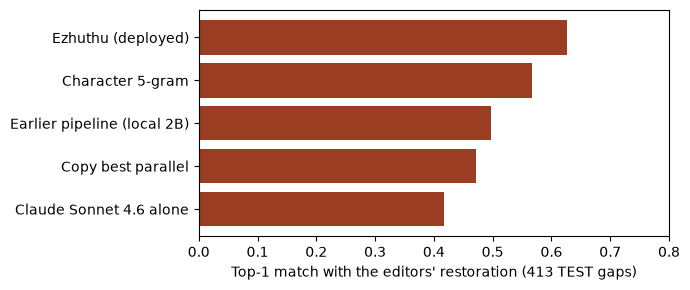

In [14]:
import matplotlib.pyplot as plt

summary = json.loads(Path("app/web/src/benchmark/summary.json").read_text())
rows = summary["leaderboard"]["full"]["rows"]
names = {"deployed": "Ezhuthu (deployed)", "ngram": "Character 5-gram", "routed2b": "Earlier pipeline (local 2B)",
         "copy": "Copy best parallel", "sonnet": "Claude Sonnet 4.6 alone"}
for r in rows:
    p = r["vs_deployed"]["p_text"] if r.get("vs_deployed") else ""
    print(f"{names.get(r['id'], r['id']):30s} top-1 {r['top1']:.4f}  CI {r['ci']}  {('p = ' + p) if p else ''}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh([names.get(r["id"], r["id"]) for r in rows][::-1], [r["top1"] for r in rows][::-1], color="#9B3D22")
ax.set_xlabel("Top-1 match with the editors' restoration (413 TEST gaps)"); ax.set_xlim(0, 0.8)
plt.tight_layout(); plt.show()

In [15]:
dep = json.loads(Path("eval/reports/2026-11-02-deployed-config.json").read_text())
f = dep["by_subset"]["full"]
print("deployed configuration:", dep["label"])
print(f"TEST n={f['n']}  top-1 {f['top1']:.4f} {f['top1_ci']}  ECE {f['ece']:.3f}")
print(f"coverage {f['coverage']:.4f}  selective accuracy {f['selective_accuracy']:.4f} ({f['filled_matching']}/{f['filled']} fills match)")

deployed configuration: b2. Routed + prerank with the 5-gram share as a noisy-OR term
TEST n=413  top-1 0.6271 [0.5787, 0.6731]  ECE 0.110
coverage 0.4988  selective accuracy 0.9078 (187/206 fills match)


In [16]:
ft = json.loads(Path("eval/reports/2026-11-02-finetuned-decider.json").read_text())
print("fine-tuned decider report sections:", list(ft)[:12])
print('''
TEST, 413 gaps (Sonnet 4.6 candidates)            top-1
  Restorer ranked by the fine-tuned decider        0.6538  (270/413, CI 0.6077-0.6973)
  Same candidates, decider-free pre-rank           0.5908  (32 vs 6 discordant, p = 2.4e-5)
  Decider only: fine-tuned vs hosted v19           0.5472 vs 0.4310  (53 vs 5, p < 1e-8)
  After calibration: fills 57.6% of gaps, 92.0% of those fills match (ECE 0.070)
''')

fine-tuned decider report sections: ['meta', 'val_restorer', 'val_decisions', 'val_calibration', 'test_restorer_sonnet', 'test_rows', 'test_bench60_rows', 'test_bench60_decider_bench', 'test_bench60_pairs', 'tutor_policy']

TEST, 413 gaps (Sonnet 4.6 candidates)            top-1
  Restorer ranked by the fine-tuned decider        0.6538  (270/413, CI 0.6077-0.6973)
  Same candidates, decider-free pre-rank           0.5908  (32 vs 6 discordant, p = 2.4e-5)
  Decider only: fine-tuned vs hosted v19           0.5472 vs 0.4310  (53 vs 5, p < 1e-8)
  After calibration: fills 57.6% of gaps, 92.0% of those fills match (ECE 0.070)



**What the numbers say.** On 413 held-out TEST gaps the pre-rank restorer (what the live app ran before it switched to
the fine-tuned decider) matches the editors' restoration on 62.7%
(259 of 413), above a character 5-gram (34 vs 9 discordant gaps, p = 0.0002) and copying the best parallel passage
(p < 0.0001). When it commits, 9 in 10 of its fills match (187 of 206, 90.8%); the rest go to an expert. Long gaps stay
hard (19.6% on gaps of 4 or more letters). The fine-tuned Strands Decider improves the ranking of the same Sonnet 4.6
candidates from 0.5908 to 0.6538. The live app now ranks with it; that routed configuration has not been scored on
TEST, so 62.7% stays the figure for the configuration scored before the switch.

**Honest limits.** The Reader cannot read Tamil-Brahmi photos yet; the ontology hints made no measurable difference to
restoration accuracy (they supply the history in lessons); learner gain is not measured yet (the pre-test and post-test
are built, and a pilot with AWS UG Madurai student volunteers is next).

## 9. Deploy your own on AWS

Five AWS CDK stacks in TypeScript (`infra/`): EzhuthuData (DynamoDB), EzhuthuAuth (Cognito), EzhuthuAgent (Amazon
Bedrock AgentCore Runtime), EzhuthuApi (API Gateway HTTP API + Lambda proxy) and EzhuthuWeb (S3 + CloudFront).

```bash
cd app/web && npm ci && npm run build && cd ../..
cd infra && npm ci
npx cdk deploy --all -c ezhuthu:budgetEmail=you@example.com
```

Model IDs live only in `config/models.yaml`; to let the restorer use the fine-tuned decider, serve
`sparrow-decider/ezhuthu-sparrow-decider-2b` with `strands-decider serve` (or a hosted decider) and set
`decider.cloud.restorer_model`. Full steps: [`infra/README.md`](../infra/README.md).

## Credits and licences

Inscription texts: the [DHARMA](https://dharmalekha.info) project (ERC grant 809994) and the editors of each edition,
CC BY-SA 4.0; the derived benchmark is CC BY-SA 4.0. Code: Apache-2.0. Fine-tuned model: Apache-2.0, built on Strands
Decider v1-2610 and Qwen3.5-2B-Base. Built with Strands Agents on Amazon Bedrock AgentCore by Vivek Raja, AWS AI Hero.